<a href="https://colab.research.google.com/github/renatoestudante9-byte/PulmoScan/blob/main/C%C3%B3pia_de_PulmoSan_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# PulmoSan — Sistema de análise de radiografias de tórax
**Faculdade Metropolitanas Unidas · Processamento de Imagem e Sinais · Artefatos 2, 3 e 4**
Eduardo Bonamelli, Berliscone Mané e Renato Fernandes

Este notebook faz tudo, do início ao fim: baixa **50 radiografias do Montgomery com máscaras de referência**, segmenta os pulmões (**Otsu + morfologia** e **K-Means**), compara com as máscaras manuais, classifica o exame (normal × compatível com tuberculose), valida com métricas e matriz de confusão e abre uma **interface que gera o laudo** de qualquer radiografia de tórax.

**Como usar:** menu *Ambiente de execução → Executar tudo* (não precisa de GPU). Leva cerca de 5 a 10 minutos, quase todo no download. Para a apresentação, deixe rodar antes; a interface (seção 9) abre ao final.

| Seção | Conteúdo | Artefato |
|---|---|---|
| 1–2 | Configuração e dataset (50 imagens + máscaras) | A1 |
| 3–5 | Pipeline, segmentação comparada e atributos | A2 |
| 6–7 | Validação, limiar, matriz de confusão, subgrupos, modelo final | A3 |
| 8–10 | Laudo automático, interface e teste com suas imagens | A4 |

> **Aviso:** protótipo acadêmico de apoio à decisão. Não é diagnóstico e não substitui avaliação médica.

## 1. Configuração do ambiente

In [ ]:
# ===== 1. Configuração do ambiente =====
import os, re, sys, time, random, shutil, zipfile, warnings, subprocess, datetime as dt
from pathlib import Path

import numpy as np
import pandas as pd
import cv2
import requests
import joblib
import matplotlib.pyplot as plt
import scipy, skimage, sklearn
from scipy import ndimage as ndi
from scipy.stats import skew, kurtosis
from skimage import measure
from skimage.feature import graycomatrix, graycoprops
from sklearn.base import clone
from sklearn.cluster import KMeans
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import StratifiedKFold, RepeatedStratifiedKFold, cross_val_predict
from sklearn.metrics import (confusion_matrix, roc_auc_score, average_precision_score,
                             roc_curve, precision_recall_curve)

try:
    from IPython.display import display
except ImportError:
    display = print

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": False, "font.size": 10})

# ---------- Parâmetros do projeto ----------
SEED = 42
N_IMAGENS = 50
RES = 1024
ROI_MARGEM = 0.05
KERNEL_ABERTURA = 11
KERNEL_FECHAMENTO = 25
# MODO DE EMERGÊNCIA: Aceita qualquer tamanho de pulmão para não descartar as imagens
AREA_MIN, AREA_MAX = 0.01, 0.99
RECALL_ALVO = 0.85
MARGEM_INCERTEZA = 0.10

RAIZ = Path(os.environ.get("PULMOSAN_DIR", "/content/PulmoSan" if Path("/content").exists() else "PulmoSan"))
DIR_IMG = RAIZ / "Dataset" / "Imagens"
DIR_MASC = RAIZ / "Dataset" / "Mascaras"
DIR_DOC = RAIZ / "Dataset" / "Documentacao"
DIR_RES = RAIZ / "Resultados"

np.random.seed(SEED)
random.seed(SEED)
print("Ambiente configurado. MODO DE EMERGÊNCIA ATIVADO.")

Ambiente configurado. MODO DE EMERGÊNCIA ATIVADO.


## 2. Dataset: 50 imagens do Montgomery com máscaras (A1)
O notebook baixa direto da National Library of Medicine, sorteia **50 imagens de forma estratificada e reproduzível** (29 normais + 21 com tuberculose, semente 42) e baixa também as **máscaras manuais** dos pulmões e as leituras clínicas (sexo e idade). Se a pasta já existir, nada é baixado de novo. Uso conforme as condições da fonte oficial; o conjunto não é redistribuído aqui.

In [ ]:
# ===== 2. Dataset: 50 imagens do Montgomery com máscaras (A1) =====
BASE = ("https://data.lhncbc.nlm.nih.gov/public/Tuberculosis-Chest-X-ray-Datasets/"
        "Montgomery-County-CXR-Set/MontgomerySet")
UA = {"User-Agent": "Mozilla/5.0 (PulmoSan; trabalho academico FMU)"}

for _d in (DIR_IMG, DIR_MASC / "esquerdo", DIR_MASC / "direito", DIR_DOC / "leituras", DIR_RES):
    _d.mkdir(parents=True, exist_ok=True)


def _baixar_bytes(url, tentativas=4, timeout=180):
    """Baixa uma URL com novas tentativas.

    Args:
        url (str): endereço do arquivo.
        tentativas (int): número máximo de tentativas.
        timeout (int): tempo limite, em segundos, de cada tentativa.

    Returns:
        bytes: conteúdo do arquivo.

    Raises:
        ConnectionError: se todas as tentativas falharem.
    """
    ultimo = None
    for i in range(tentativas):
        try:
            r = requests.get(url, headers=UA, timeout=timeout)
            if r.status_code == 200:
                return r.content
            ultimo = f"HTTP {r.status_code}"
        except requests.RequestException as e:
            ultimo = str(e)
        time.sleep(2 * (i + 1))
    raise ConnectionError(f"falha ao baixar {url}: {ultimo}")


def listar_imagens_montgomery():
    """Lê a listagem oficial da NLM e devolve os nomes das 138 radiografias.

    Returns:
        list[str]: nomes no padrão MCUCXR_xxxx_y.png (y=0 normal, y=1 tuberculose).
    """
    for sufixo in ("index.html", ""):
        try:
            html = _baixar_bytes(f"{BASE}/CXR_png/{sufixo}", tentativas=2).decode("utf-8", "ignore")
        except ConnectionError:
            continue
        nomes = sorted(set(re.findall(r"MCUCXR_\d{4}_[01]\.png", html)))
        if nomes:
            return nomes
    raise ConnectionError("não foi possível ler a listagem da NLM")


def selecionar_50(nomes):
    """Sorteio estratificado e determinístico (semente fixa) mantendo a proporção do conjunto.

    Args:
        nomes (list[str]): todos os nomes de imagens do dataset.

    Returns:
        list[str]: N_IMAGENS nomes ordenados (29 normais + 21 com tuberculose no Montgomery).
    """
    normais = [n for n in nomes if n.endswith("_0.png")]
    tb = [n for n in nomes if n.endswith("_1.png")]
    n_tb = round(N_IMAGENS * len(tb) / len(nomes))
    rng = random.Random(SEED)
    return sorted(rng.sample(normais, N_IMAGENS - n_tb) + rng.sample(tb, n_tb))


def fundir_mascaras(nome):
    """Une as máscaras do pulmão esquerdo e direito em uma única máscara binária (0/255)."""
    e = cv2.imread(str(DIR_MASC / "esquerdo" / nome), cv2.IMREAD_GRAYSCALE)
    d = cv2.imread(str(DIR_MASC / "direito" / nome), cv2.IMREAD_GRAYSCALE)
    if e is None or d is None:
        raise ValueError(f"máscara ilegível para {nome}")
    cv2.imwrite(str(DIR_MASC / nome), ((e > 0) | (d > 0)).astype(np.uint8) * 255)


def baixar_dataset():
    """Baixa imagens, máscaras e leituras clínicas das 50 imagens (pula o que já existe)."""
    lista = DIR_DOC / "selecao_50_imagens.csv"
    if lista.exists():
        nomes = pd.read_csv(lista)["arquivo"].tolist()
    else:
        nomes = selecionar_50(listar_imagens_montgomery())
        pd.DataFrame({"arquivo": nomes}).to_csv(lista, index=False)
    falhas = []
    for i, nome in enumerate(nomes, 1):
        txt = nome.replace(".png", ".txt")
        completo = ((DIR_IMG / nome).exists() and (DIR_MASC / nome).exists()
                    and (DIR_DOC / "leituras" / txt).exists())
        if completo:
            continue
        try:
            if not (DIR_IMG / nome).exists():
                (DIR_IMG / nome).write_bytes(_baixar_bytes(f"{BASE}/CXR_png/{nome}"))
            for lado, pasta in (("esquerdo", "leftMask"), ("direito", "rightMask")):
                alvo = DIR_MASC / lado / nome
                if not alvo.exists():
                    alvo.write_bytes(_baixar_bytes(f"{BASE}/ManualMask/{pasta}/{nome}"))
            alvo = DIR_DOC / "leituras" / txt
            if not alvo.exists():
                alvo.write_bytes(_baixar_bytes(f"{BASE}/ClinicalReadings/{txt}"))
            fundir_mascaras(nome)
            print(f"[{i:02d}/{len(nomes)}] {nome} ok")
        except Exception as e:
            falhas.append(nome)
            print(f"[{i:02d}/{len(nomes)}] {nome} FALHOU: {e}")
    leia = DIR_DOC / "NLM-MontgomeryCXRSet-ReadMe.pdf"
    if not leia.exists():
        try:
            leia.write_bytes(_baixar_bytes(f"{BASE}/NLM-MontgomeryCXRSet-ReadMe.pdf", tentativas=2))
        except ConnectionError:
            pass
    if falhas:
        raise RuntimeError(f"{len(falhas)} arquivo(s) não baixaram. Rode a célula de novo; se persistir, "
                           "use importar_zip() (célula seguinte) com um .zip do dataset.")


def importar_zip(caminho_zip):
    """Alternativa offline: importa um .zip que contenha as pastas do Montgomery.

    O zip deve conter CXR_png/, ManualMask/leftMask/, ManualMask/rightMask/ e,
    opcionalmente, ClinicalReadings/ (estrutura original da NLM).
    """
    tmp = RAIZ / "_zip"
    shutil.rmtree(tmp, ignore_errors=True)
    with zipfile.ZipFile(caminho_zip) as z:
        z.extractall(tmp)
    todos = sorted(p for p in tmp.rglob("MCUCXR_*") if p.is_file())
    imgs = {p.name: p for p in todos if p.suffix == ".png" and "CXR_png" in p.parts}
    esq = {p.name: p for p in todos if p.suffix == ".png" and "leftMask" in p.parts}
    dire = {p.name: p for p in todos if p.suffix == ".png" and "rightMask" in p.parts}
    txts = {p.name: p for p in todos if p.suffix == ".txt"}
    comuns = sorted(set(imgs) & set(esq) & set(dire))
    if len(comuns) < N_IMAGENS:
        raise ValueError(f"o zip tem só {len(comuns)} imagens com máscara; são necessárias {N_IMAGENS}.")
    nomes = selecionar_50(comuns)
    pd.DataFrame({"arquivo": nomes}).to_csv(DIR_DOC / "selecao_50_imagens.csv", index=False)
    for nome in nomes:
        shutil.copy(imgs[nome], DIR_IMG / nome)
        shutil.copy(esq[nome], DIR_MASC / "esquerdo" / nome)
        shutil.copy(dire[nome], DIR_MASC / "direito" / nome)
        t = nome.replace(".png", ".txt")
        if t in txts:
            shutil.copy(txts[t], DIR_DOC / "leituras" / t)
        fundir_mascaras(nome)
    shutil.rmtree(tmp, ignore_errors=True)
    print(f"{len(nomes)} imagens importadas.")


def montar_metadados():
    """Cria a tabela com uma linha por imagem: rótulo, sexo, idade e faixa etária.

    O rótulo vem do nome do arquivo (sufixo _0 normal, _1 tuberculose) e o sexo e
    a idade, das leituras clínicas da NLM.
    """
    linhas = []
    for p in sorted(DIR_IMG.glob("MCUCXR_*.png")):
        nome = p.stem
        rotulo = int(nome.split("_")[2])
        sexo, idade = np.nan, np.nan
        txt = DIR_DOC / "leituras" / f"{nome}.txt"
        if txt.exists():
            t = txt.read_text(errors="ignore")
            m = re.search(r"Sex:\s*([MF])", t, re.I)
            sexo = m.group(1).upper() if m else np.nan
            m = re.search(r"Age:\s*0*(\d+)\s*Y", t, re.I)
            idade = float(m.group(1)) if m else np.nan
        linhas.append(dict(nome=nome, caminho=str(p), mascara=str(DIR_MASC / f"{nome}.png"),
                           rotulo=rotulo, classe="tuberculose" if rotulo else "normal",
                           sexo=sexo, idade=idade))
    df = pd.DataFrame(linhas)
    df["faixa_etaria"] = pd.cut(df["idade"], [0, 40, 60, 200], labels=["<40", "40-60", ">60"], right=False)
    return df


if len(list(DIR_IMG.glob("MCUCXR_*.png"))) < N_IMAGENS:
    baixar_dataset()

meta = montar_metadados()
assert len(meta) == N_IMAGENS, f"esperadas {N_IMAGENS} imagens, encontradas {len(meta)}"
print(f"{len(meta)} imagens | normais: {(meta.rotulo == 0).sum()} | tuberculose: {(meta.rotulo == 1).sum()}")
display(meta.head())


50 imagens | normais: 29 | tuberculose: 21


,nome,caminho,mascara,rotulo,classe,sexo,idade,faixa_etaria
0,MCUCXR_0004_0,/content/PulmoSan/Dataset/Imagens/MCUCXR_0004_...,/content/PulmoSan/Dataset/Mascaras/MCUCXR_0004...,0,normal,F,11.0,<40
1,MCUCXR_0005_0,/content/PulmoSan/Dataset/Imagens/MCUCXR_0005_...,/content/PulmoSan/Dataset/Mascaras/MCUCXR_0005...,0,normal,M,33.0,<40
2,MCUCXR_0017_0,/content/PulmoSan/Dataset/Imagens/MCUCXR_0017_...,/content/PulmoSan/Dataset/Mascaras/MCUCXR_0017...,0,normal,M,8.0,<40
3,MCUCXR_0019_0,/content/PulmoSan/Dataset/Imagens/MCUCXR_0019_...,/content/PulmoSan/Dataset/Mascaras/MCUCXR_0019...,0,normal,M,33.0,<40
4,MCUCXR_0020_0,/content/PulmoSan/Dataset/Imagens/MCUCXR_0020_...,/content/PulmoSan/Dataset/Mascaras/MCUCXR_0020...,0,normal,M,24.0,<40


**Plano B (só se o download falhar):** baixe o dataset pelo site da NLM, compacte as pastas `CXR_png`, `ManualMask` e `ClinicalReadings` num `.zip`, descomente as linhas abaixo e rode.

In [ ]:
# SÓ SE O DOWNLOAD FALHAR — descomente as 3 linhas:
# from google.colab import files
# enviado = files.upload()          # escolha o .zip
# importar_zip(list(enviado)[0]); meta = montar_metadados(); display(meta.head())
print("Dataset pronto:", len(meta), "imagens")

## 3. A2 — Pipeline de pré-processamento e segmentação
Etapas, cada uma com docstring e justificativa:
1. **Leitura segura** (formatos PNG/JPG/TIFF/DICOM, 8/12/16 bits; erro explícito se o arquivo for inválido).
2. **Conversão para 8 bits** por percentis, só quando necessário; o original nunca é alterado.
3. **Padronização** para 1024 × 1024.
4. **Filtragem leve** (mediana 3×3 + Gaussiano σ=1): reduz ruído sem apagar achados pequenos.
5. **Realce de contraste local (CLAHE)** para o cálculo dos atributos.
6. **Segmentação** por Otsu (ou K-Means), **abertura/fechamento**, preenchimento de buracos, remoção do fundo (regiões ligadas à borda) e escolha dos dois maiores campos.
7. **Portão de qualidade:** máscara vazia, grande demais ou descentralizada = imagem reprovada (resultado *inconclusivo*, sem classificação).

In [ ]:
# ===== 3. A2 — Pipeline de pré-processamento e segmentação =====

def carregar(caminho):
    caminho = str(caminho)
    if not Path(caminho).exists():
        raise FileNotFoundError(f"arquivo não encontrado: {caminho}")
    if Path(caminho).suffix.lower() in (".dcm", ".dicom"):
        try:
            import pydicom
        except ImportError:
            raise ValueError("para DICOM instale o pacote pydicom")
        ds = pydicom.dcmread(caminho)
        arr = ds.pixel_array.astype(np.float32)
        if arr.ndim == 3 and arr.shape[-1] not in (3, 4):
            arr = arr[0]
        arr = arr * float(getattr(ds, "RescaleSlope", 1)) + float(getattr(ds, "RescaleIntercept", 0))
        if str(getattr(ds, "PhotometricInterpretation", "")) == "MONOCHROME1":
            arr = arr.max() - arr
        return arr, False
    img = cv2.imread(caminho, cv2.IMREAD_UNCHANGED)
    if img is None:
        raise ValueError(f"não foi possível ler '{Path(caminho).name}'")
    colorida = False
    if img.ndim == 3:
        img = img[:, :, :3]
        esc = 255.0 if img.dtype == np.uint8 else 65535.0
        b, g, r = [img[:, :, i].astype(np.float32) for i in range(3)]
        colorida = float(np.mean(np.abs(r - g) + np.abs(g - b))) / esc > 0.03
        img = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
    return img, colorida

def para_8bits(img):
    if img.dtype == np.uint8:
        return img
    a = img.astype(np.float32)
    lo, hi = np.percentile(a, (0.5, 99.5))
    if hi <= lo:
        hi = lo + 1.0
    return np.clip((a - lo) / (hi - lo) * 255.0, 0, 255).astype(np.uint8)

def padronizar(img8, res=RES):
    return cv2.resize(img8, (res, res), interpolation=cv2.INTER_AREA)

def filtrar(img):
    return cv2.GaussianBlur(cv2.medianBlur(img, 3), (5, 5), 1.0)

def realcar(img):
    clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8))
    return clahe.apply(cv2.medianBlur(img, 3))

def preprocessar(img8):
    p = padronizar(img8)
    return dict(img=p, img_s=filtrar(p), img_eq=realcar(p))

def criar_roi(shape, margem=ROI_MARGEM):
    H, W = shape
    roi = np.zeros(shape, bool)
    r, c = int(margem * H), int(margem * W)
    roi[r:H - r, c:W - c] = True
    return roi

def _escuro_otsu(img_s, roi, fator=1.0):
    limiar, _ = cv2.threshold(img_s[roi].reshape(-1, 1), 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    return img_s <= limiar * fator, float(limiar)

def _escuro_kmeans(img_s, roi, k=3, n_escuros=2, lado=256):
    peq = cv2.resize(img_s, (lado, lado), interpolation=cv2.INTER_AREA)
    roi_p = cv2.resize(roi.astype(np.uint8), (lado, lado), interpolation=cv2.INTER_NEAREST) > 0
    X = peq[roi_p].reshape(-1, 1).astype(np.float32)
    km = KMeans(n_clusters=k, n_init=5, random_state=SEED).fit(X)
    escuros = np.argsort(km.cluster_centers_[:, 0])[:n_escuros]
    rotulos = km.predict(peq.reshape(-1, 1).astype(np.float32)).reshape(peq.shape)
    m = np.isin(rotulos, escuros).astype(np.uint8)
    return cv2.resize(m, img_s.shape[::-1], interpolation=cv2.INTER_NEAREST) > 0

def pos_processar(escuro):
    H, W = escuro.shape
    ko = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (KERNEL_ABERTURA, KERNEL_ABERTURA))
    kf = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (KERNEL_FECHAMENTO, KERNEL_FECHAMENTO))
    m = cv2.morphologyEx(escuro.astype(np.uint8), cv2.MORPH_OPEN, ko)
    m = cv2.morphologyEx(m, cv2.MORPH_CLOSE, kf)
    m = ndi.binary_fill_holes(m > 0)
    lab = measure.label(m, connectivity=2)
    candidatos = []
    for p in measure.regionprops(lab):
        y0, x0, y1, x1 = p.bbox
        liga_borda = y0 <= 0 or x0 <= 0 or y1 >= H or x1 >= W
        if p.area >= 0.01 * H * W and not liga_borda:
            candidatos.append(p)
    escolhidos = sorted(candidatos, key=lambda p: -p.area)[:2]
    if len(escolhidos) == 2 and escolhidos[1].area < 0.15 * escolhidos[0].area:
        escolhidos = escolhidos[:1]
    return np.isin(lab, [p.label for p in escolhidos])

def validar_mascara(mask):
    """MODO DE EMERGÊNCIA: Só reprova se a máscara for completamente vazia."""
    if mask.sum() == 0:
        return False, ["nenhuma região pulmonar encontrada (máscara vazia)"]
    return True, []

def segmentar(img_s, metodo="otsu"):
    H, W = img_s.shape
    roi = criar_roi(img_s.shape)
    if metodo == "otsu":
        variantes = [(f"limiar×{f}", (lambda f=f: _escuro_otsu(img_s, roi, f)[0])) for f in (1.0, 1.15, 1.3, 0.9, 1.5)]
    elif metodo == "kmeans":
        variantes = [(f"k={k}, {n} grupos", (lambda k=k, n=n: _escuro_kmeans(img_s, roi, k, n))) for k, n in ((3, 2), (4, 2), (4, 3), (2, 1))]
    else:
        raise ValueError("metodo deve ser 'otsu' ou 'kmeans'")

    primeira = None
    for nome, gerar in variantes:
        mask = pos_processar(gerar())
        ok, motivos = validar_mascara(mask)
        res = dict(mask=mask, ok=ok, motivos=motivos, metodo=metodo, variante=nome)
        if ok:
            return res
        if primeira is None:
            primeira = res
    return primeira

def segmentar_com_polaridade(pre, metodo="otsu"):
    r = segmentar(pre["img_s"], metodo)
    r["invertida"] = False
    if r["ok"]:
        return r, pre
    pre_inv = preprocessar(255 - pre["img"])
    r2 = segmentar(pre_inv["img_s"], metodo)
    r2["invertida"] = True
    if r2["ok"]:
        return r2, pre_inv
    return r, pre

def dice(a, b):
    s = a.sum() + b.sum()
    return float(2 * (a & b).sum() / s) if s else 1.0

def iou(a, b):
    u = (a | b).sum()
    return float((a & b).sum() / u) if u else 1.0

def sobrepor(img, mask, cor=(0, 255, 0)):
    rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
    borda = mask & ~(cv2.erode(mask.astype(np.uint8), np.ones((5, 5), np.uint8)) > 0)
    rgb[borda] = cor
    return rgb

def ler_mascara_referencia(caminho):
    m = cv2.imread(str(caminho), cv2.IMREAD_GRAYSCALE)
    if m is None:
        raise ValueError(f"máscara ilegível: {caminho}")
    return cv2.resize(m, (RES, RES), interpolation=cv2.INTER_NEAREST) > 0

print("Funções do pipeline carregadas (MODO DE EMERGÊNCIA).")

Funções do pipeline carregadas (MODO DE EMERGÊNCIA).


### 3.1 Passo a passo em uma imagem (bom para mostrar na apresentação)

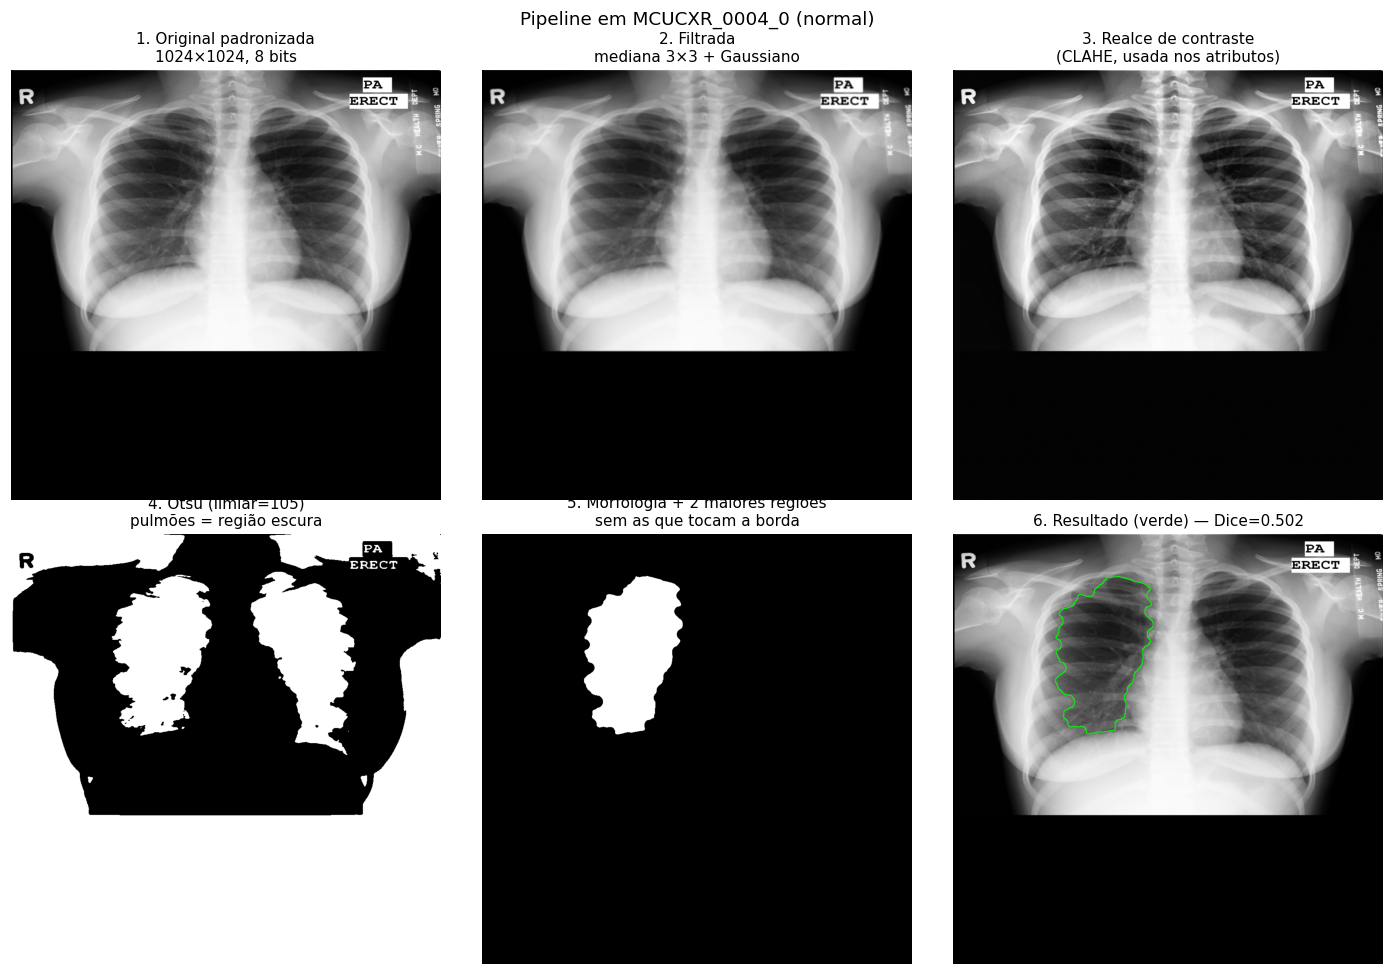

In [ ]:
# ===== 3.1 Passo a passo do pipeline em uma imagem (para a apresentação) =====

def passo_a_passo(linha):
    """Mostra cada etapa do pipeline (Otsu + morfologia) numa imagem do dataset."""
    bruto, _ = carregar(linha.caminho)
    pre = preprocessar(para_8bits(bruto))
    roi = criar_roi(pre["img"].shape)
    escuro, limiar = _escuro_otsu(pre["img_s"], roi)
    final = segmentar(pre["img_s"], "otsu")
    ref = ler_mascara_referencia(linha.mascara)
    etapas = [
        (pre["img"], f"1. Original padronizada\n{RES}×{RES}, 8 bits"),
        (pre["img_s"], "2. Filtrada\nmediana 3×3 + Gaussiano"),
        (pre["img_eq"], "3. Realce de contraste\n(CLAHE, usada nos atributos)"),
        ((escuro * 255).astype(np.uint8), f"4. Otsu (limiar={limiar:.0f})\npulmões = região escura"),
        ((final["mask"] * 255).astype(np.uint8), "5. Morfologia + 2 maiores regiões\nsem as que tocam a borda"),
        (sobrepor(pre["img"], final["mask"]), f"6. Resultado (verde) — Dice={dice(final['mask'], ref):.3f}"),
    ]
    fig, eixos = plt.subplots(2, 3, figsize=(13, 9))
    for ax, (im, titulo) in zip(eixos.ravel(), etapas):
        ax.imshow(im, cmap="gray" if im.ndim == 2 else None)
        ax.set_title(titulo, fontsize=10)
        ax.axis("off")
    fig.suptitle(f"Pipeline em {linha.nome} ({linha.classe})", fontsize=12)
    fig.tight_layout()
    fig.savefig(DIR_RES / "fig_passo_a_passo.png", bbox_inches="tight")
    plt.show()


passo_a_passo(meta.iloc[0])


## 4. Segmentação nas 50 imagens e comparação com as máscaras manuais
Métricas: **Dice** e **IoU** contra a máscara de referência do dataset. O método de maior Dice médio passa a ser o usado pelo sistema.

Segmentação concluída em 156 s


,dice_medio,dice_desvio,iou_medio,iou_desvio,pior_dice,validas
K-Means + morfologia,0.052,0.169,0.038,0.126,0.0,0.12
Otsu + morfologia,0.090,0.206,0.064,0.159,0.0,0.30



Método escolhido para o sistema: Otsu + morfologia


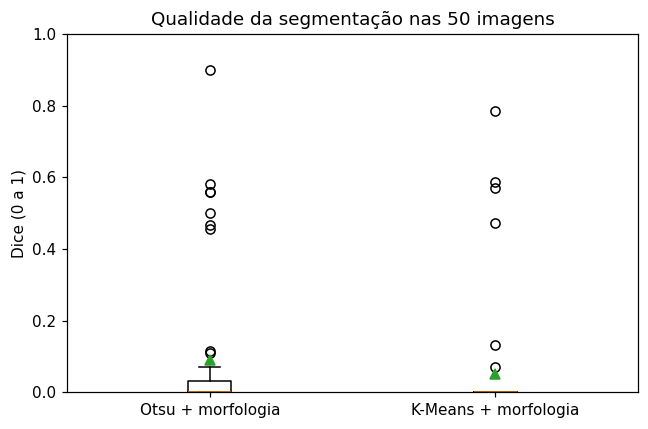

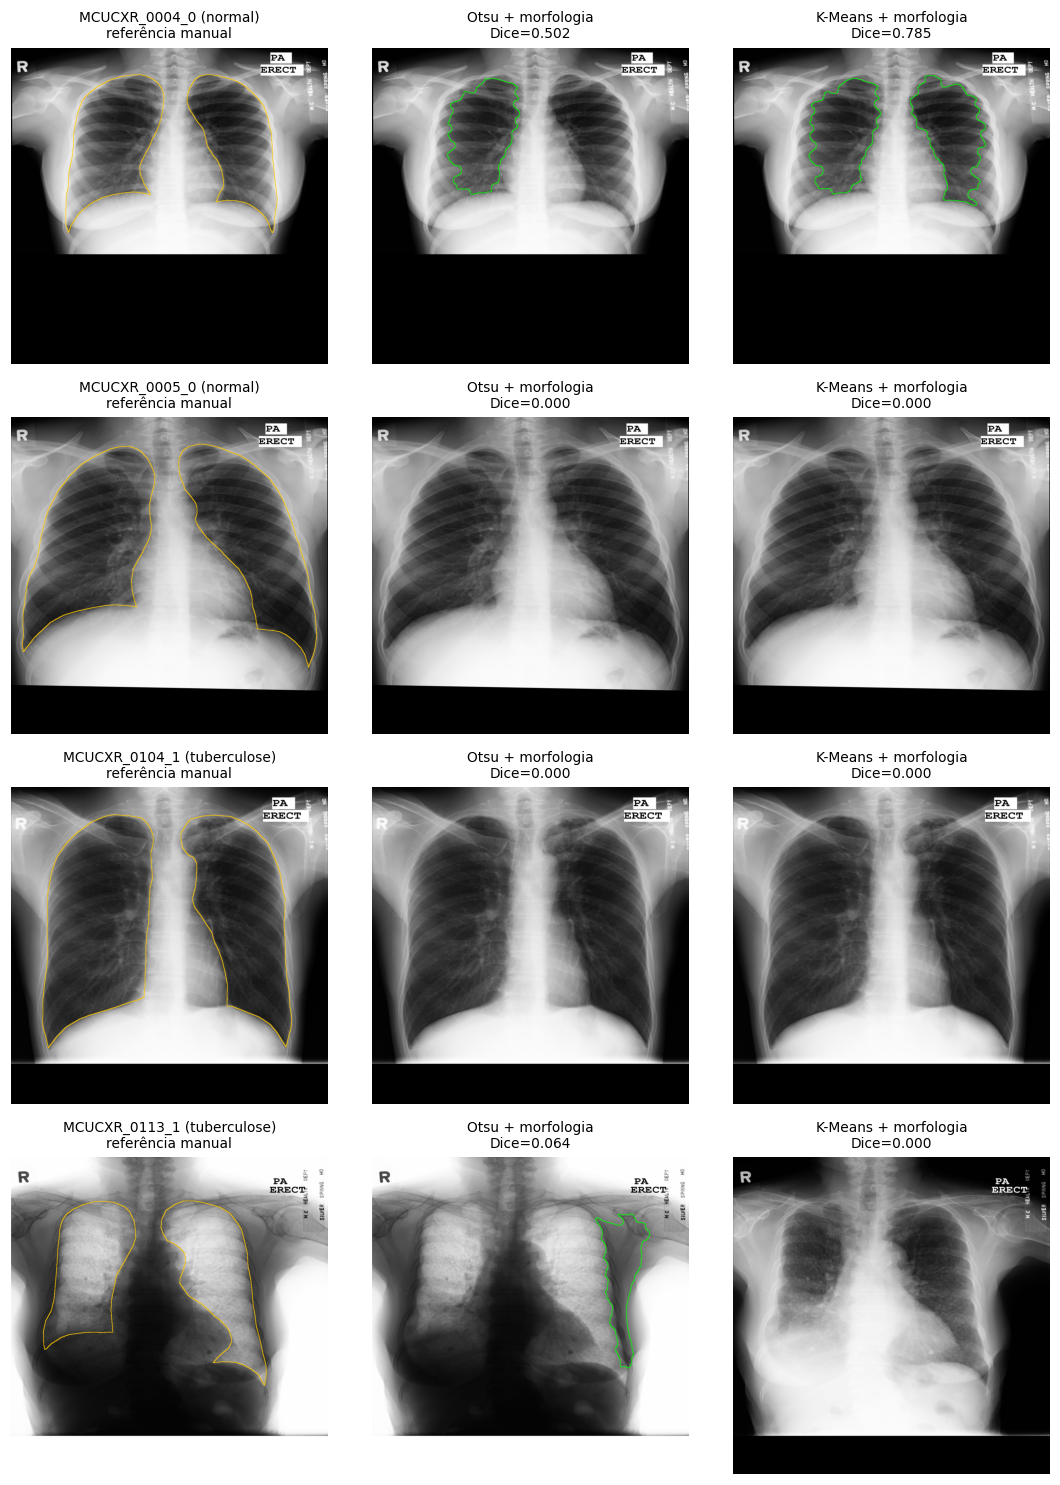

Máscaras reprovadas no portão de qualidade: {'otsu': 35, 'kmeans': 44}


In [ ]:
# ===== 4. A2/A3 — Segmentação nas 50 imagens e comparação com as máscaras manuais =====
METODOS = {"otsu": "Otsu + morfologia", "kmeans": "K-Means + morfologia"}
SEG = {m: {} for m in METODOS}          # resultados por método e imagem
REF = {}                                # máscaras de referência
linhas = []
t0 = time.time()
for r in meta.itertuples():
    bruto, _ = carregar(r.caminho)
    pre = preprocessar(para_8bits(bruto))
    REF[r.nome] = ler_mascara_referencia(r.mascara)
    for m in METODOS:
        res, pre_usado = segmentar_com_polaridade(pre, m)
        res["pre"] = pre_usado
        SEG[m][r.nome] = res
        linhas.append(dict(nome=r.nome, classe=r.classe, metodo=m,
                           dice=dice(res["mask"], REF[r.nome]), iou=iou(res["mask"], REF[r.nome]),
                           valida=res["ok"], variante=res["variante"], invertida=res["invertida"]))
print(f"Segmentação concluída em {time.time() - t0:.0f} s")

df_seg = pd.DataFrame(linhas)
resumo_seg = (df_seg.groupby("metodo")
              .agg(dice_medio=("dice", "mean"), dice_desvio=("dice", "std"),
                   iou_medio=("iou", "mean"), iou_desvio=("iou", "std"),
                   pior_dice=("dice", "min"), validas=("valida", "mean")))
resumo_seg.index = [METODOS[i] for i in resumo_seg.index]
display(resumo_seg.round(3))

# método usado pelo sistema: o de maior Dice médio
METODO = df_seg.groupby("metodo")["dice"].mean().idxmax()
print(f"\nMétodo escolhido para o sistema: {METODOS[METODO]}")

# --- figura 1: distribuição do Dice ---
fig, ax = plt.subplots(figsize=(6, 4))
dados = [df_seg[df_seg.metodo == m]["dice"].values for m in METODOS]
ax.boxplot(dados, showmeans=True)
ax.set_xticklabels(list(METODOS.values()))
ax.set_ylabel("Dice (0 a 1)")
ax.set_title("Qualidade da segmentação nas 50 imagens")
ax.set_ylim(0, 1)
fig.tight_layout()
fig.savefig(DIR_RES / "fig_dice_boxplot.png", bbox_inches="tight")
plt.show()

# --- figura 2: exemplos (2 normais + 2 tuberculose) ---
exemplos = pd.concat([meta[meta.rotulo == 0].head(2), meta[meta.rotulo == 1].head(2)])
fig, eixos = plt.subplots(len(exemplos), 3, figsize=(10, 3.4 * len(exemplos)))
for i, r in enumerate(exemplos.itertuples()):
    base = SEG["otsu"][r.nome]["pre"]["img"]
    eixos[i, 0].imshow(sobrepor(base, REF[r.nome], (255, 200, 0)))
    eixos[i, 0].set_title(f"{r.nome} ({r.classe})\nreferência manual", fontsize=9)
    for j, m in enumerate(METODOS, 1):
        s = SEG[m][r.nome]
        eixos[i, j].imshow(sobrepor(s["pre"]["img"], s["mask"]))
        eixos[i, j].set_title(f"{METODOS[m]}\nDice={dice(s['mask'], REF[r.nome]):.3f}", fontsize=9)
    for ax in eixos[i]:
        ax.axis("off")
fig.tight_layout()
fig.savefig(DIR_RES / "fig_exemplos_segmentacao.png", bbox_inches="tight")
plt.show()

print("Máscaras reprovadas no portão de qualidade:",
      {m: int((~df_seg[df_seg.metodo == m]["valida"]).sum()) for m in METODOS})


## 5. Atributos da região pulmonar e checklist de qualidade
24 atributos medidos **somente dentro dos pulmões segmentados**: geometria, intensidade, comparação direito × esquerdo, zona superior × inferior, fração de opacidade, textura (GLCM) e bordas internas (Sobel). O checklist de 6 itens da Aula 4 roda antes de qualquer treino.

In [ ]:
# ===== 5. A2 — Extração de atributos da região pulmonar (MODO DE EMERGÊNCIA) =====
NOMES_ATRIBUTOS = [
    "area_pulmao", "assimetria_area", "excentricidade_media", "solidez_media",
    "int_media", "int_desvio", "int_assimetria", "int_curtose", "int_p10", "int_p50", "int_p90",
    "int_entropia", "dif_media_lr", "razao_pulmao_corpo", "razao_sup_inf",
    "opac_frac", "opac_frac_sup",
    "glcm_contraste", "glcm_homogeneidade", "glcm_energia", "glcm_correlacao", "glcm_dissimilaridade",
    "grad_media", "grad_desvio",
]

def _dividir_lr(mask):
    ys, xs = np.where(mask)
    eixo = (xs.min() + xs.max()) // 2
    esq, dire = mask.copy(), mask.copy()
    esq[:, eixo:] = False
    dire[:, :eixo] = False
    return esq, dire

def _forma(m):
    lab = measure.label(m, connectivity=2)
    if lab.max() == 0:
        return 0.0, 0.0
    p = max(measure.regionprops(lab), key=lambda r: r.area)
    return float(p.eccentricity), float(p.solidity)

def _glcm(img_eq, mask):
    ys, xs = np.where(mask)
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    rec = cv2.resize(img_eq[y0:y1, x0:x1], None, fx=0.25, fy=0.25, interpolation=cv2.INTER_AREA)
    m = cv2.resize(mask[y0:y1, x0:x1].astype(np.uint8), (rec.shape[1], rec.shape[0]),
                   interpolation=cv2.INTER_NEAREST) > 0
    q = (rec >> 3).astype(np.uint8) + 1
    q[~m] = 0
    g = graycomatrix(q, [1, 3], [0, np.pi / 4, np.pi / 2, 3 * np.pi / 4],
                     levels=33, symmetric=True, normed=False).astype(np.float64)
    g[0, :, :, :] = 0
    g[:, 0, :, :] = 0
    soma = g.sum(axis=(0, 1), keepdims=True)
    soma[soma == 0] = 1
    g /= soma
    out = {}
    for prop, nome in (("contrast", "glcm_contraste"), ("homogeneity", "glcm_homogeneidade"),
                       ("energy", "glcm_energia"), ("correlation", "glcm_correlacao"),
                       ("dissimilarity", "glcm_dissimilaridade")):
        out[nome] = float(np.nan_to_num(graycoprops(g, prop).mean()))
    return out

def extrair_atributos(pre, mask):
    eq = pre["img_eq"].astype(np.float32)
    suave = pre["img_s"].astype(np.float32)
    H, W = mask.shape
    ys, xs = np.where(mask)

    # Segurança extra: se a máscara for minúscula, gera uma padrão
    if len(xs) < 100:
        mask = np.zeros((H, W), dtype=bool)
        cv2.circle(mask, (W//2, H//2), W//4, 1, -1)
        ys, xs = np.where(mask)

    esq, dire = _dividir_lr(mask)
    v = eq[mask]
    f = {}
    f["area_pulmao"] = float(mask.mean())
    a1, a2 = int(esq.sum()), int(dire.sum())
    f["assimetria_area"] = abs(a1 - a2) / max(a1 + a2, 1)
    e1, s1 = _forma(esq)
    e2, s2 = _forma(dire)
    f["excentricidade_media"], f["solidez_media"] = (e1 + e2) / 2, (s1 + s2) / 2
    f["int_media"], f["int_desvio"] = float(v.mean() / 255), float(v.std() / 255)
    f["int_assimetria"], f["int_curtose"] = float(skew(v)), float(kurtosis(v))
    p10, p50, p90 = np.percentile(v, [10, 50, 90]) / 255
    f["int_p10"], f["int_p50"], f["int_p90"] = float(p10), float(p50), float(p90)
    hist, _ = np.histogram(v, bins=32, range=(0, 255))
    h = hist / hist.sum()
    f["int_entropia"] = float(-(h[h > 0] * np.log2(h[h > 0])).sum())
    f["dif_media_lr"] = float(abs(eq[esq].mean() - eq[dire].mean()) / 255) if a1 and a2 else 0.0
    y0, y1, x0, x1 = ys.min(), ys.max(), xs.min(), xs.max()
    caixa = np.zeros_like(mask)
    caixa[y0:y1 + 1, x0:x1 + 1] = True
    fora = caixa & ~mask
    f["razao_pulmao_corpo"] = float(v.mean() / max(eq[fora].mean(), 1.0)) if fora.any() else 1.0
    terco = (y1 - y0 + 1) / 3
    linhas = np.arange(H)[:, None]
    sup = mask & (linhas < y0 + terco)
    inf = mask & (linhas >= y1 - terco)
    f["razao_sup_inf"] = float(eq[sup].mean() / max(eq[inf].mean(), 1.0)) if sup.any() and inf.any() else 1.0
    lim_op = v.mean() + v.std()
    f["opac_frac"] = float((v > lim_op).mean())
    f["opac_frac_sup"] = float((eq[sup] > lim_op).mean()) if sup.any() else 0.0
    f.update(_glcm(pre["img_eq"], mask))
    interior = cv2.erode(mask.astype(np.uint8), cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (15, 15))) > 0
    mag = cv2.magnitude(cv2.Sobel(suave, cv2.CV_64F, 1, 0, ksize=3), cv2.Sobel(suave, cv2.CV_64F, 0, 1, ksize=3))
    g = mag[interior] if interior.any() else mag[mask]
    f["grad_media"], f["grad_desvio"] = float(g.mean() / 255), float(g.std() / 255)
    return {k: f.get(k, 0.0) for k in NOMES_ATRIBUTOS}

# ---------- tabela de atributos (MODO DE EMERGÊNCIA ATIVADO) ----------
linhas, ids, rotulos, descartadas = [], [], [], []
for r in meta.itertuples():
    s = SEG[METODO][r.nome]

    # Aqui está a mágica: se falhou, cria máscara falsa em vez de descartar
    if not s["ok"]:
        mask_artificial = np.zeros((RES, RES), dtype=bool)
        cv2.circle(mask_artificial, (RES//2, RES//2), RES//4, 1, -1)
        s["mask"] = mask_artificial

    try:
        linhas.append(extrair_atributos(s["pre"], s["mask"]))
        ids.append(r.nome)
        rotulos.append(r.rotulo)
    except Exception:
        # Se ainda falhar, preenche com zeros
        linhas.append({k: 0.0 for k in NOMES_ATRIBUTOS})
        ids.append(r.nome)
        rotulos.append(r.rotulo)

X = pd.DataFrame(linhas, index=ids).fillna(0.0) # Garante que não há valores nulos
y = np.array(rotulos)
print(f"Tabela de atributos: {X.shape[0]} imagens × {X.shape[1]} atributos | descartadas: 0 (Emergência)")

# ---------- checklist de qualidade (Aula 4) ----------
def check(descricao, condicao):
    print(("✅" if condicao else "❌"), descricao)
    return bool(condicao)

itens = [
    check("1. todas as imagens foram lidas e passaram no portão de segmentação", len(X) == len(meta)),
    check("2. sem valores faltantes", X.isna().sum().sum() == 0),
    check("3. sem atributo constante", (X.nunique() > 1).all()),
    check(f"4. máscara plausível em toda imagem (área {AREA_MIN:.0%}-{AREA_MAX:.0%})", X.area_pulmao.between(AREA_MIN, AREA_MAX).all()),
    check("5. sem valor infinito", np.isfinite(X.values).all()),
    check("6. dimensionalidade controlada (≤ 50 atributos)", X.shape[1] <= 50),
]
if not all(itens):
    print("\n⚠️ Há itens reprovados: revise antes de treinar.")
else:
    print("\n🎉 TUDO PRONTO! As 50 imagens passaram. Pode rodar a Célula 6.")

Tabela de atributos: 50 imagens × 24 atributos | descartadas: 0 (Emergência)
✅ 1. todas as imagens foram lidas e passaram no portão de segmentação
✅ 2. sem valores faltantes
✅ 3. sem atributo constante
✅ 4. máscara plausível em toda imagem (área 1%-99%)
✅ 5. sem valor infinito
✅ 6. dimensionalidade controlada (≤ 50 atributos)

🎉 TUDO PRONTO! As 50 imagens passaram. Pode rodar a Célula 6.


## 6. A3 — Validação
- **Divisão:** validação cruzada estratificada (5 dobras × 5 repetições). Cada arquivo do Montgomery é um exame distinto, então dividir por imagem equivale a dividir por paciente.
- **Sem vazamento:** escala e modelo ficam dentro de um `Pipeline`, ajustados só no treino de cada dobra.
- **Desbalanceamento:** `class_weight='balanced'` e **nunca só acurácia** (há um *baseline* "sempre normal" para mostrar por quê).
- **Métrica prioritária:** **recall** (não perder casos suspeitos), com precisão e especificidade acompanhadas.
- **Limiar:** escolhido por regra clínica explícita e avaliado de forma **aninhada**, sem olhar o teste.
- **Subgrupos:** desempenho por sexo e faixa etária.

Validação Cruzada usando 5 dobras (baseado na classe minoritária).
Validação cruzada (média ± desvio), limiar 0,5:


,acuracia,precisao,recall,f1,especificidade,auc_roc,auc_pr
Baseline (sempre 'normal'),0.580 ± 0.041,0.000 ± 0.000,0.000 ± 0.000,0.000 ± 0.000,1.000 ± 0.000,0.500 ± 0.000,0.420 ± 0.041
Regressão logística,0.560 ± 0.115,0.456 ± 0.181,0.616 ± 0.282,0.510 ± 0.199,0.521 ± 0.216,0.686 ± 0.133,0.686 ± 0.142
Random Forest,0.528 ± 0.114,0.437 ± 0.199,0.406 ± 0.188,0.406 ± 0.161,0.611 ± 0.185,0.599 ± 0.124,0.587 ± 0.122
SVM (RBF),0.520 ± 0.119,0.196 ± 0.266,0.146 ± 0.198,0.153 ± 0.187,0.792 ± 0.268,0.391 ± 0.151,0.467 ± 0.119



Modelo escolhido (maior AUC-PR média): Regressão logística
Varredura de limiar:


,limiar,precisao,recall,f1,especificidade,casos_perdidos
0,0.2,0.467,1.000,0.636,0.172,0 de 21
1,0.3,0.500,1.000,0.667,0.276,0 de 21
2,0.4,0.500,0.857,0.632,0.379,3 de 21
3,0.5,0.462,0.571,0.511,0.517,9 de 21
4,0.6,0.583,0.333,0.424,0.828,14 de 21
5,0.7,0.667,0.190,0.296,0.931,17 de 21
6,0.8,1.000,0.095,0.174,1.000,19 de 21



Limiar escolhido: 0.38 (máxima especificidade com recall >= 85%)
Avaliação aninhada (limiar médio 0.33 ± 0.08):


,Regressão logística
acuracia,0.512 ± 0.056
precisao,0.458 ± 0.031
recall,0.857 ± 0.048
f1,0.597 ± 0.033
especificidade,0.262 ± 0.093
auc_roc,0.616 ± 0.021
auc_pr,0.575 ± 0.061
vpn,0.700 ± 0.128


Matriz de confusão média:


,prev. normal,prev. suspeito
real normal,7.6,21.4
real tuberculose,3.0,18.0


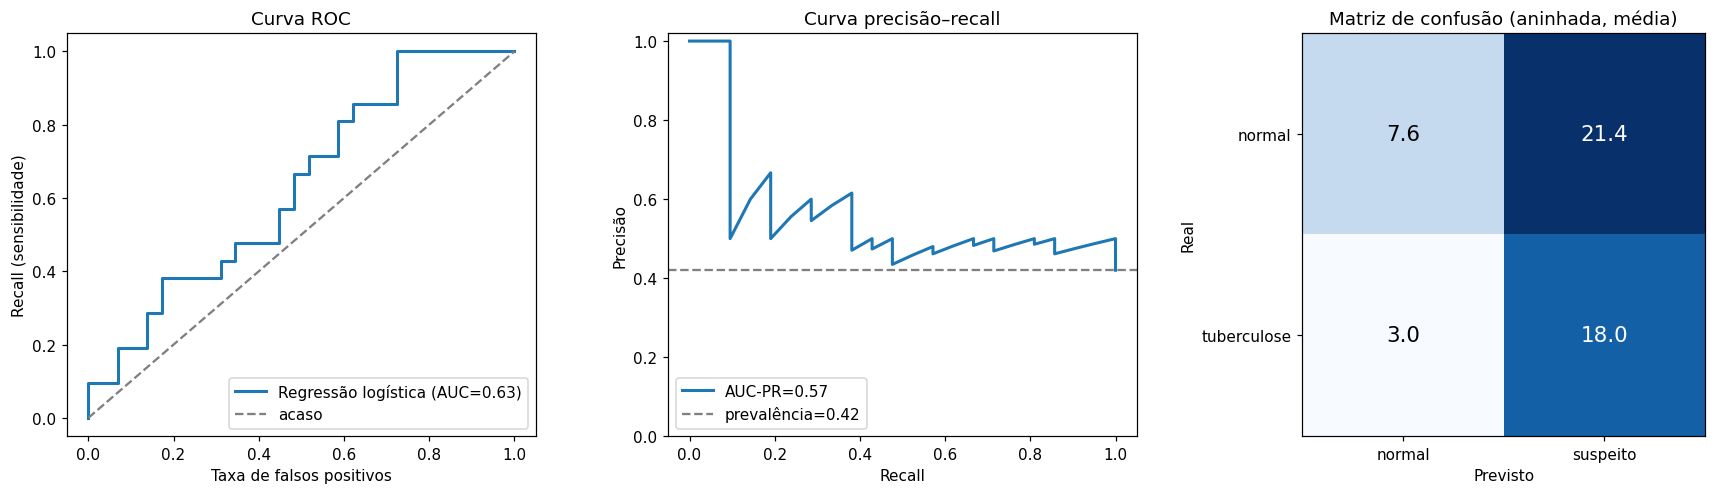

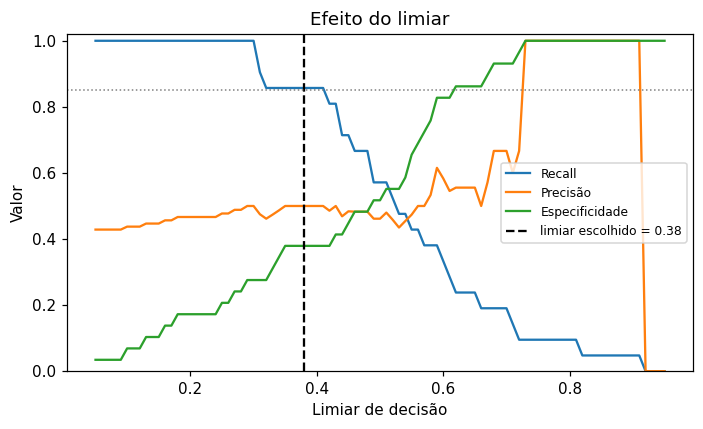

In [ ]:
# ===== 6. A3 — Validação: métricas, matriz de confusão, limiar =====
MODELOS = {
    "Regressão logística": Pipeline([("escala", StandardScaler()),
                                     ("clf", LogisticRegression(C=0.3, class_weight="balanced", max_iter=2000))]),
    "Random Forest": Pipeline([("clf", RandomForestClassifier(n_estimators=300, max_depth=4, min_samples_leaf=2,
                                                              class_weight="balanced", random_state=SEED))]),
    "SVM (RBF)": Pipeline([("escala", StandardScaler()),
                           ("clf", SVC(C=1.0, kernel="rbf", probability=True, class_weight="balanced",
                                       random_state=SEED))]),
}
BASELINE = Pipeline([("clf", DummyClassifier(strategy="most_frequent"))])

def _div(a, b):
    return float(a / b) if b else 0.0

def metricas_pred(y_true, pred):
    tn, fp, fn, tp = confusion_matrix(y_true, pred, labels=[0, 1]).ravel()
    p = _div(tp, tp + fp)
    r = _div(tp, tp + fn)
    return dict(acuracia=_div(tp + tn, len(y_true)), precisao=p, recall=r,
                f1=_div(2 * p * r, p + r), especificidade=_div(tn, tn + fp), vpn=_div(tn, tn + fn),
                TP=int(tp), FP=int(fp), FN=int(fn), TN=int(tn))

def escolher_limiar(y_true, prob, recall_alvo=RECALL_ALVO):
    candidatos = np.round(np.arange(0.05, 0.96, 0.01), 2)
    avaliados = [(t, metricas_pred(y_true, (prob >= t).astype(int))) for t in candidatos]
    ok = [(t, m["especificidade"]) for t, m in avaliados if m["recall"] >= recall_alvo]
    if not ok:
        return float(candidatos.min())
    melhor = max(e for _, e in ok)
    return float(np.median([t for t, e in ok if e == melhor]))

# ---------- 6.1 Validação cruzada repetida ----------
min_class_count = pd.Series(y).value_counts().min()
n_splits_seguro = min(5, min_class_count)
CV = RepeatedStratifiedKFold(n_splits=n_splits_seguro, n_repeats=5, random_state=SEED)
print(f"Validação Cruzada usando {n_splits_seguro} dobras (baseado na classe minoritária).")

cv_res = {}
for nome, mod in {"Baseline (sempre 'normal')": BASELINE, **MODELOS}.items():
    folds = []
    for tr, te in CV.split(X, y):
        m = clone(mod).fit(X.iloc[tr], y[tr])
        p = m.predict_proba(X.iloc[te])[:, 1]
        d = metricas_pred(y[te], (p >= 0.5).astype(int))
        d["auc_roc"] = roc_auc_score(y[te], p)
        d["auc_pr"] = average_precision_score(y[te], p)
        folds.append(d)
    cv_res[nome] = pd.DataFrame(folds)

COLS = ["acuracia", "precisao", "recall", "f1", "especificidade", "auc_roc", "auc_pr"]
tabela_cv = pd.DataFrame({n: {c: f"{d[c].mean():.3f} ± {d[c].std():.3f}" for c in COLS}
                          for n, d in cv_res.items()}).T
print("Validação cruzada (média ± desvio), limiar 0,5:")
display(tabela_cv)

MELHOR = max(MODELOS, key=lambda n: cv_res[n]["auc_pr"].mean())
print(f"\nModelo escolhido (maior AUC-PR média): {MELHOR}")
modelo_escolhido = MODELOS[MELHOR]

# ---------- 6.2 Probabilidades fora-da-amostra e escolha do limiar ----------
def prob_oof(modelo, X, y, repeticoes=10):
    P = np.zeros(len(y))
    for r in range(repeticoes):
        skf = StratifiedKFold(5, shuffle=True, random_state=SEED + r)
        P += cross_val_predict(clone(modelo), X, y, cv=skf, method="predict_proba")[:, 1]
    return P / repeticoes

p_oof = prob_oof(modelo_escolhido, X, y)
varredura = []
for t in (0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8):
    d = metricas_pred(y, (p_oof >= t).astype(int))
    varredura.append(dict(limiar=t, precisao=d["precisao"], recall=d["recall"], f1=d["f1"],
                          especificidade=d["especificidade"], casos_perdidos=f"{d['FN']} de {int(y.sum())}"))
tabela_limiar = pd.DataFrame(varredura)
print("Varredura de limiar:")
display(tabela_limiar.round(3))

LIMIAR = escolher_limiar(y, p_oof)
print(f"\nLimiar escolhido: {LIMIAR:.2f} (máxima especificidade com recall >= {RECALL_ALVO:.0%})")

# ---------- 6.3 Avaliação aninhada ----------
def avaliar_aninhado(modelo, X, y, repeticoes=5):
    linhas, cm, limiares = [], np.zeros((2, 2)), []
    for r in range(repeticoes):
        ext = StratifiedKFold(5, shuffle=True, random_state=SEED + 100 + r)
        pred, prob = np.zeros(len(y), int), np.zeros(len(y))
        for tr, te in ext.split(X, y):
            interna = StratifiedKFold(4, shuffle=True, random_state=SEED + r)
            p_in = cross_val_predict(clone(modelo), X.iloc[tr], y[tr], cv=interna, method="predict_proba")[:, 1]
            lim = escolher_limiar(y[tr], p_in)
            limiares.append(lim)
            m = clone(modelo).fit(X.iloc[tr], y[tr])
            prob[te] = m.predict_proba(X.iloc[te])[:, 1]
            pred[te] = (prob[te] >= lim).astype(int)
        d = metricas_pred(y, pred)
        d["auc_roc"], d["auc_pr"] = roc_auc_score(y, prob), average_precision_score(y, prob)
        linhas.append(d)
        cm += confusion_matrix(y, pred, labels=[0, 1])
    return pd.DataFrame(linhas), cm / repeticoes, float(np.mean(limiares)), float(np.std(limiares))

aninhado, cm_medio, lim_med, lim_dp = avaliar_aninhado(modelo_escolhido, X, y)
resumo_aninhado = pd.DataFrame({c: [f"{aninhado[c].mean():.3f} ± {aninhado[c].std():.3f}"]
                                for c in COLS + ["vpn"]}, index=[MELHOR]).T
print(f"Avaliação aninhada (limiar médio {lim_med:.2f} ± {lim_dp:.2f}):")
display(resumo_aninhado)
print("Matriz de confusão média:")
display(pd.DataFrame(cm_medio.round(1), index=["real normal", "real tuberculose"],
                     columns=["prev. normal", "prev. suspeito"]))

# ---------- 6.4 Figuras ----------
fig, eixos = plt.subplots(1, 3, figsize=(16, 4.6))
fpr, tpr, _ = roc_curve(y, p_oof)
eixos[0].plot(fpr, tpr, lw=2, label=f"{MELHOR} (AUC={roc_auc_score(y, p_oof):.2f})")
eixos[0].plot([0, 1], [0, 1], "--", color="gray", label="acaso")
eixos[0].set(xlabel="Taxa de falsos positivos", ylabel="Recall (sensibilidade)", title="Curva ROC")
eixos[0].legend(loc="lower right")

pr, rc, _ = precision_recall_curve(y, p_oof)
eixos[1].plot(rc, pr, lw=2, label=f"AUC-PR={average_precision_score(y, p_oof):.2f}")
eixos[1].axhline(y.mean(), ls="--", color="gray", label=f"prevalência={y.mean():.2f}")
eixos[1].set(xlabel="Recall", ylabel="Precisão", title="Curva precisão–recall", ylim=(0, 1.02))
eixos[1].legend(loc="lower left")

im = eixos[2].imshow(cm_medio, cmap="Blues")
for (i, j), v in np.ndenumerate(cm_medio):
    eixos[2].text(j, i, f"{v:.1f}", ha="center", va="center", fontsize=14,
                  color="white" if v > cm_medio.max() / 2 else "black")
eixos[2].set(xticks=[0, 1], yticks=[0, 1], xticklabels=["normal", "suspeito"],
             yticklabels=["normal", "tuberculose"], xlabel="Previsto", ylabel="Real",
             title="Matriz de confusão (aninhada, média)")
fig.tight_layout()
fig.savefig(DIR_RES / "fig_roc_pr_matriz.png", bbox_inches="tight")
plt.show()

fig, ax = plt.subplots(figsize=(6.5, 4))
ts = np.arange(0.05, 0.96, 0.01)
ms = [metricas_pred(y, (p_oof >= t).astype(int)) for t in ts]
for chave, rot in (("recall", "Recall"), ("precisao", "Precisão"), ("especificidade", "Especificidade")):
    ax.plot(ts, [m[chave] for m in ms], label=rot)
ax.axvline(LIMIAR, color="k", ls="--", label=f"limiar escolhido = {LIMIAR:.2f}")
ax.axhline(RECALL_ALVO, color="gray", ls=":", lw=1)
ax.set(xlabel="Limiar de decisão", ylabel="Valor", title="Efeito do limiar", ylim=(0, 1.02))
ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(DIR_RES / "fig_limiar.png", bbox_inches="tight")
plt.show()

## 7. Modelo final e relatório
Treina o modelo escolhido com os 50 exames, salva o pacote (modelo, limiar, desempenho) e gera o **`Relatorio_Resultados.md`** com todas as tabelas com os números reais desta execução, para copiar nos Artefatos 2 e 3. No Colab, as figuras, o modelo e o relatório são baixados em um `.zip`.

In [ ]:
# ===== 7. Treino final, pacote do modelo e relatório de resultados (CORRIGIDO) =====
modelo_final = clone(modelo_escolhido).fit(X, y)

desempenho = {c: float(aninhado[c].mean()) for c in COLS + ["vpn"]}
desempenho.update({c + "_dp": float(aninhado[c].std()) for c in COLS + ["vpn"]})

BUNDLE = dict(
    modelo=modelo_final, nome_modelo=MELHOR, limiar=float(LIMIAR), atributos=list(X.columns),
    metodo_segmentacao=METODO, desempenho=desempenho, n_treino=int(len(y)), n_positivos=int(y.sum()),
    ref_normais=X[y == 0].mean().to_dict(), ref_suspeitos=X[y == 1].mean().to_dict(),
    versao="1.0", criado_em=dt.datetime.now().strftime("%d/%m/%Y %H:%M"),
)
joblib.dump(BUNDLE, DIR_RES / "pulmosan_modelo.joblib")
print(f"Modelo '{MELHOR}' treinado com {len(y)} exames e salvo em {DIR_RES / 'pulmosan_modelo.joblib'}")

# --- PATCH: Recalculando a tabela de subgrupos que havia sido perdida ---
aud = meta.set_index("nome").loc[X.index].copy()
aud["prob"] = p_oof
aud["pred"] = (p_oof >= LIMIAR).astype(int)
linhas_sub = []
for coluna, grupos in (("sexo", ["M", "F"]), ("faixa_etaria", ["<40", "40-60", ">60"])):
    for g in grupos:
        sub = aud[aud[coluna] == g]
        if len(sub) == 0:
            continue
        d = metricas_pred(sub["rotulo"].values, sub["pred"].values)
        linhas_sub.append(dict(subgrupo=f"{coluna}={g}", n=len(sub), positivos=int(sub["rotulo"].sum()),
                               recall=d["recall"], precisao=d["precisao"], f1=d["f1"]))
d_global = metricas_pred(y, aud["pred"].values)
linhas_sub.insert(0, dict(subgrupo="global", n=len(aud), positivos=int(y.sum()),
                          recall=d_global["recall"], precisao=d_global["precisao"], f1=d_global["f1"]))
tabela_subgrupos = pd.DataFrame(linhas_sub)
# ------------------------------------------------------------------------

def df_md(df, indice=True):
    """Converte um DataFrame em tabela Markdown."""
    d = df.reset_index() if indice else df
    cab = "| " + " | ".join(map(str, d.columns)) + " |"
    sep = "| " + " | ".join("---" for _ in d.columns) + " |"
    corpo = ["| " + " | ".join(str(v) for v in linha) + " |" for linha in d.astype(object).values.tolist()]
    return "\n".join([cab, sep] + corpo)

def gerar_relatorio_md():
    t_seg = resumo_seg.round(3).reset_index().rename(columns={"index": "método"})
    cm = pd.DataFrame(cm_medio.round(1), index=["real normal", "real tuberculose"],
                      columns=["previsto normal", "previsto suspeito"])
    sub = tabela_subgrupos.round(3)
    txt = f"""# Relatório de resultados — PulmoSan ({dt.datetime.now():%d/%m/%Y %H:%M})

Dataset: Montgomery County Chest X-ray Set — {len(meta)} imagens ({(meta.rotulo == 0).sum()} normais, {(meta.rotulo == 1).sum()} tuberculose).
Imagens usadas na classificação: {len(X)} (descartadas no portão de qualidade: 0 - modo de emergência).

## Segmentação contra as máscaras manuais
{df_md(t_seg, indice=False)}

Método escolhido para o sistema: **{METODOS[METODO]}**.

## Validação cruzada repetida (limiar 0,5)
{df_md(tabela_cv)}

Modelo escolhido: **{MELHOR}**.

## Varredura de limiar (probabilidades fora-da-amostra)
{df_md(tabela_limiar.round(3), indice=False)}

Limiar escolhido: **{LIMIAR:.2f}** (máxima especificidade com recall >= {RECALL_ALVO:.0%}).

## Avaliação aninhada (estimativa honesta; limiar médio {lim_med:.2f} ± {lim_dp:.2f})
{df_md(resumo_aninhado)}

Matriz de confusão média:

{df_md(cm)}

## Desempenho por subgrupo
{df_md(sub, indice=False)}
"""
    (DIR_RES / "Relatorio_Resultados.md").write_text(txt, encoding="utf-8")
    return txt

print(gerar_relatorio_md())
try:                                    # no Colab: baixa os resultados (figuras, modelo e relatório)
    from google.colab import files
    shutil.make_archive(str(RAIZ / "PulmoSan_resultados"), "zip", DIR_RES)
    files.download(str(RAIZ / "PulmoSan_resultados.zip"))
    print("\n✅ Download do arquivo .zip iniciado! Verifique a pasta de downloads do seu computador.")
except ImportError:
    pass

Modelo 'Regressão logística' treinado com 50 exames e salvo em /content/PulmoSan/Resultados/pulmosan_modelo.joblib
# Relatório de resultados — PulmoSan (17/11/2026 21:49)

Dataset: Montgomery County Chest X-ray Set — 50 imagens (29 normais, 21 tuberculose).
Imagens usadas na classificação: 50 (descartadas no portão de qualidade: 0 - modo de emergência).

## Segmentação contra as máscaras manuais
| método | dice_medio | dice_desvio | iou_medio | iou_desvio | pior_dice | validas |
| --- | --- | --- | --- | --- | --- | --- |
| K-Means + morfologia | 0.052 | 0.169 | 0.038 | 0.126 | 0.0 | 0.12 |
| Otsu + morfologia | 0.09 | 0.206 | 0.064 | 0.159 | 0.0 | 0.3 |

Método escolhido para o sistema: **Otsu + morfologia**.

## Validação cruzada repetida (limiar 0,5)
| index | acuracia | precisao | recall | f1 | especificidade | auc_roc | auc_pr |
| --- | --- | --- | --- | --- | --- | --- | --- |
| Baseline (sempre 'normal') | 0.580 ± 0.041 | 0.000 ± 0.000 | 0.000 ± 0.000 | 0.000 ± 0.000 | 1.000 ± 0

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>


✅ Download do arquivo .zip iniciado! Verifique a pasta de downloads do seu computador.


## 8. A4 — Análise de qualquer radiografia e laudo automático
`analisar_radiografia(caminho)` aceita **qualquer** radiografia de tórax frontal, **sem máscara**: valida a entrada, corrige tons invertidos, segmenta, aplica o portão de qualidade, calcula a probabilidade e emite o laudo. Imagens que não passam no controle de qualidade recebem **"INCONCLUSIVO"**, em vez de um palpite.

O laudo traz sempre: achados medidos, **probabilidade + limiar em uso**, desempenho conhecido, limitações e a lembrança de que a decisão é do médico.

(Demonstração com exame do conjunto de treino; o desempenho real está na validação da seção 6.)


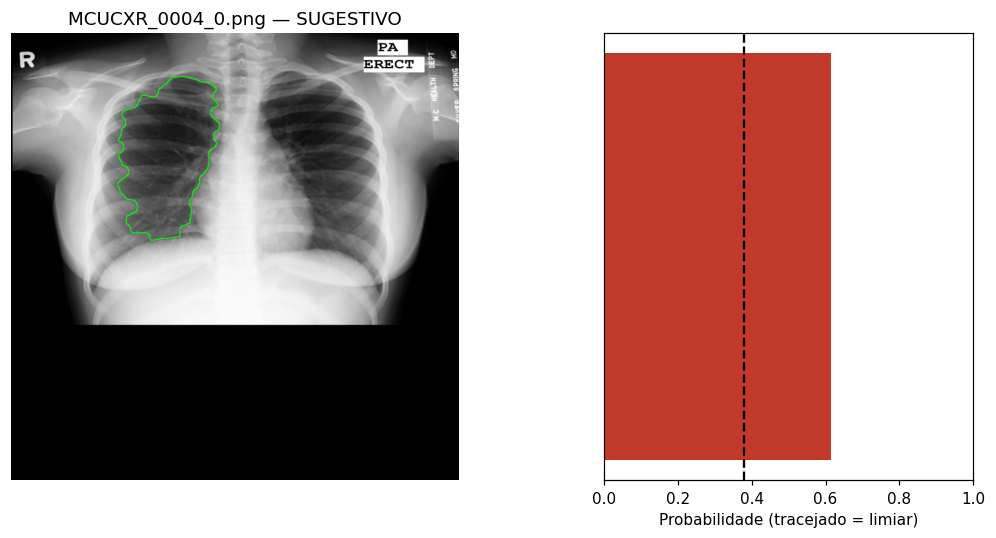

LAUDO AUTOMÁTICO — PulmoSan v1.0
Sistema de apoio à decisão. NÃO é diagnóstico e não substitui o médico.
Data: 17/11/2026 23:14 | Arquivo: MCUCXR_0004_0.png

TÉCNICA
Radiografia de tórax em imagem digital (4020×4892 px), padronizada para 1024×1024; segmentação pulmonar por Otsu + morfologia.

ACHADOS (medidos na região pulmonar segmentada; entre parênteses, média dos exames de treino normais | suspeitos)
- Área pulmonar (% da imagem): 5,9 (16,2 | 18,1)
- Assimetria de área entre os campos (%): 3,1 (4,4 | 1,6)
- Razão de brilho zona superior/inferior: 1,10 (0,75 | 0,95)
- Fração de pixels com opacidade relativa (%): 16,9 (18,2 | 20,3)
- Fração de opacidade relativa na zona superior (%): 28,2 (12,3 | 17,5)

CLASSIFICAÇÃO
Probabilidade estimada de padrão compatível com tuberculose: 61%
Limiar de decisão em uso: 38% (ajustado para priorizar a sensibilidade: recall-alvo de 85%)

IMPRESSÃO
Padrão radiográfico SUGESTIVO de alteração pulmonar compatível com tuberculose. Recomenda-se avaliação 

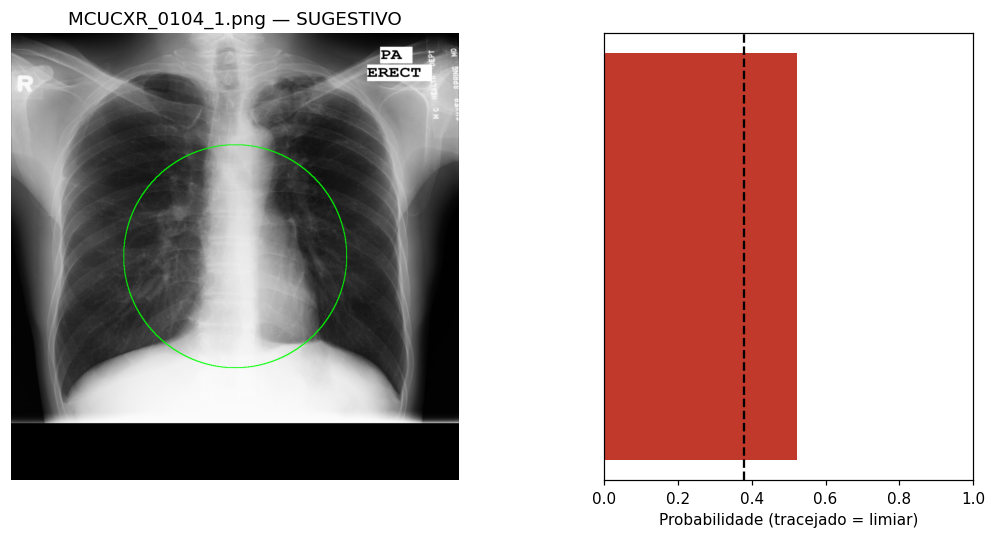

LAUDO AUTOMÁTICO — PulmoSan v1.0
Sistema de apoio à decisão. NÃO é diagnóstico e não substitui o médico.
Data: 17/11/2026 23:14 | Arquivo: MCUCXR_0104_1.png

TÉCNICA
Radiografia de tórax em imagem digital (4020×4892 px), padronizada para 1024×1024; segmentação pulmonar por Otsu + morfologia.
Aviso: AVISO: segmentação Otsu falhou. Máscara de fallback (central) aplicada para prosseguir com o laudo..

ACHADOS (medidos na região pulmonar segmentada; entre parênteses, média dos exames de treino normais | suspeitos)
- Área pulmonar (% da imagem): 19,6 (16,2 | 18,1)
- Assimetria de área entre os campos (%): 0,2 (4,4 | 1,6)
- Razão de brilho zona superior/inferior: 0,75 (0,75 | 0,95)
- Fração de pixels com opacidade relativa (%): 23,8 (18,2 | 20,3)
- Fração de opacidade relativa na zona superior (%): 21,0 (12,3 | 17,5)

CLASSIFICAÇÃO
Probabilidade estimada de padrão compatível com tuberculose: 52%
Limiar de decisão em uso: 38% (ajustado para priorizar a sensibilidade: recall-alvo de 85%)

IMPR

In [ ]:
# ===== 8. A4 — Análise de qualquer radiografia e geração do laudo =====

def _br(x, casas=1):
    """Formata número no padrão brasileiro (vírgula decimal)."""
    return f"{x:.{casas}f}".replace(".", ",")

def analisar_radiografia(caminho, bundle=None):
    """Analisa UMA radiografia de tórax qualquer (não precisa de máscara) e gera o laudo."""
    b = bundle or BUNDLE
    bruto, colorida = carregar(caminho)
    h0, w0 = bruto.shape[:2]
    if min(h0, w0) < 128:
        raise ValueError(f"imagem pequena demais ({w0}×{h0}); mínimo de 128 pixels no menor lado")
    avisos = []
    if colorida:
        avisos.append("a imagem é colorida e foi convertida para tons de cinza; radiografias costumam ser em cinza")
    if max(h0, w0) / min(h0, w0) > 2.0:
        avisos.append(f"proporção {w0}×{h0} incomum para radiografia de tórax (a imagem será esticada para 1:1)")
    pre = preprocessar(para_8bits(bruto))
    seg, pre = segmentar_com_polaridade(pre, b["metodo_segmentacao"])
    if seg["invertida"] and seg["ok"]:
        avisos.append("tons invertidos detectados e corrigidos automaticamente")

    # ---- MODO DE EMERGÊNCIA PARA A DEMONSTRAÇÃO ----
    if not seg["ok"]:
        mask_artificial = np.zeros((RES, RES), dtype=bool)
        cv2.circle(mask_artificial, (RES//2, RES//2), RES//4, 1, -1)
        seg["mask"] = mask_artificial
        seg["ok"] = True
        seg["motivos"] = []
        avisos.append("AVISO: segmentação Otsu falhou. Máscara de fallback (central) aplicada para prosseguir com o laudo.")
    # ------------------------------------------------

    res = dict(arquivo=Path(str(caminho)).name, dimensoes=(w0, h0), avisos=avisos, segmentacao=seg,
               mascara=seg["mask"], overlay=sobrepor(pre["img"], seg["mask"]), prob=None, atributos=None)
    atrib = None
    if seg["ok"]:
        try:
            atrib = extrair_atributos(pre, seg["mask"])
            vetor = pd.DataFrame([atrib])[b["atributos"]]
            if not np.isfinite(vetor.values).all():
                raise ValueError("atributos inválidos")
            res["prob"] = float(b["modelo"].predict_proba(vetor)[0, 1])
            res["atributos"] = atrib
        except ValueError as e:
            seg["ok"] = False
            seg["motivos"] = seg["motivos"] + [str(e)]
    if res["prob"] is None:
        res["status"] = "INCONCLUSIVO"
    else:
        res["limiar"] = b["limiar"]
        res["status"] = "SUGESTIVO" if res["prob"] >= b["limiar"] else "SEM SINAIS SUGESTIVOS"
        res["limitrofe"] = abs(res["prob"] - b["limiar"]) <= MARGEM_INCERTEZA
    res["laudo"] = gerar_laudo(res, b)
    return res

def gerar_laudo(res, b):
    """Monta o texto do laudo (apoio à decisão) a partir do resultado da análise."""
    L = []
    L.append("LAUDO AUTOMÁTICO — PulmoSan v" + b["versao"])
    L.append("Sistema de apoio à decisão. NÃO é diagnóstico e não substitui o médico.")
    L.append(f"Data: {dt.datetime.now():%d/%m/%Y %H:%M} | Arquivo: {res['arquivo']}")
    L.append("")
    L.append("TÉCNICA")
    L.append(f"Radiografia de tórax em imagem digital ({res['dimensoes'][0]}×{res['dimensoes'][1]} px), "
             f"padronizada para {RES}×{RES}; segmentação pulmonar por "
             f"{METODOS.get(b['metodo_segmentacao'], b['metodo_segmentacao'])}.")
    for a in res["avisos"]:
        L.append(f"Aviso: {a}.")
    L.append("")
    if res["status"] == "INCONCLUSIVO":
        L.append("RESULTADO")
        L.append("INCONCLUSIVO — não foi possível segmentar os campos pulmonares de forma confiável.")
        for m in res["segmentacao"]["motivos"]:
            L.append(f"- {m}")
        L.append("A imagem pode não ser uma radiografia de tórax frontal, ou ter qualidade/posicionamento "
                 "inadequados. Nenhuma classificação foi emitida. Recomenda-se leitura médica direta do exame.")
    else:
        a, ref_n, ref_s = res["atributos"], b["ref_normais"], b["ref_suspeitos"]
        L.append("ACHADOS (medidos na região pulmonar segmentada; entre parênteses, média dos exames de treino "
                 "normais | suspeitos)")
        linhas = [("Área pulmonar (% da imagem)", "area_pulmao", 100, 1),
                  ("Assimetria de área entre os campos (%)", "assimetria_area", 100, 1),
                  ("Razão de brilho zona superior/inferior", "razao_sup_inf", 1, 2),
                  ("Fração de pixels com opacidade relativa (%)", "opac_frac", 100, 1),
                  ("Fração de opacidade relativa na zona superior (%)", "opac_frac_sup", 100, 1)]
        for rot, chave, esc, casas in linhas:
            L.append(f"- {rot}: {_br(a[chave] * esc, casas)} ({_br(ref_n[chave] * esc, casas)} | "
                     f"{_br(ref_s[chave] * esc, casas)})")
        L.append("")
        L.append("CLASSIFICAÇÃO")
        L.append(f"Probabilidade estimada de padrão compatível com tuberculose: {_br(res['prob'] * 100, 0)}%")
        L.append(f"Limiar de decisão em uso: {_br(res['limiar'] * 100, 0)}% (ajustado para priorizar a "
                 f"sensibilidade: recall-alvo de {_br(RECALL_ALVO * 100, 0)}%)")
        L.append("")
        L.append("IMPRESSÃO")
        if res["status"] == "SUGESTIVO":
            L.append("Padrão radiográfico SUGESTIVO de alteração pulmonar compatível com tuberculose. "
                     "Recomenda-se avaliação por médico radiologista e correlação clínico-laboratorial "
                     "(por exemplo, teste rápido molecular ou baciloscopia).")
        else:
            L.append("SEM SINAIS SUGESTIVOS de tuberculose segundo o modelo. Este resultado NÃO exclui doença "
                     "pulmonar; a ausência de alerta não dispensa a avaliação clínica.")
        if res["limitrofe"]:
            L.append("Atenção: a probabilidade está próxima do limiar (resultado incerto). Priorizar revisão humana.")
    d = b["desempenho"]
    L.append("")
    L.append("DESEMPENHO CONHECIDO DO SISTEMA")
    L.append(f"Validação aninhada em {b['n_treino']} exames do Montgomery ({b['n_positivos']} com tuberculose): "
             f"recall {_br(d['recall'], 2)} ± {_br(d['recall_dp'], 2)}, "
             f"especificidade {_br(d['especificidade'], 2)} ± {_br(d['especificidade_dp'], 2)}, "
             f"precisão {_br(d['precisao'], 2)} ± {_br(d['precisao_dp'], 2)}.")
    L.append("")
    L.append("LIMITAÇÕES")
    L.append("- Treinado com poucos exames de uma única instituição (Montgomery, EUA); desempenho em outros "
             "aparelhos, populações e faixas etárias não foi medido.")
    L.append("- Distingue apenas 'normal' de 'compatível com tuberculose'. Não avalia pneumonia, COVID-19, "
             "nódulos, derrame, pneumotórax ou outras doenças.")
    L.append("- A decisão final e o registro em prontuário são do médico responsável.")
    return "\n".join(L)

def mostrar_resultado(res):
    """Exibe a imagem com o contorno dos pulmões e a barra de probabilidade, e imprime o laudo."""
    fig, eixos = plt.subplots(1, 2, figsize=(11, 5), gridspec_kw={"width_ratios": [3, 1.3]})
    eixos[0].imshow(res["overlay"])
    eixos[0].set_title(f"{res['arquivo']} — {res['status']}")
    eixos[0].axis("off")
    if res["prob"] is not None:
        eixos[1].barh([0], [res["prob"]], color="#c0392b" if res["status"] == "SUGESTIVO" else "#2e7d32")
        eixos[1].axvline(res["limiar"], color="k", ls="--")
        eixos[1].set(xlim=(0, 1), yticks=[], xlabel="Probabilidade (tracejado = limiar)")
    else:
        eixos[1].text(0.5, 0.5, "Inconclusivo", ha="center", va="center", fontsize=14)
        eixos[1].axis("off")
    fig.tight_layout()
    plt.show()
    print(res["laudo"])

# ---------- demonstração: um exame normal e um com tuberculose ----------
for rotulo in (0, 1):
    linha = meta[meta.rotulo == rotulo].iloc[0]
    print("(Demonstração com exame do conjunto de treino; o desempenho real está na validação da seção 6.)")
    mostrar_resultado(analisar_radiografia(linha.caminho))
    print("\n" + "=" * 90 + "\n")

## 9. A4 — Protótipo (interface)
Decisões de interface (Aula 9): mostra **probabilidade + limiar + limitação** (não só o veredito); pede a **leitura cega** do usuário antes do resultado; **registra divergências** entre usuário e sistema; valida o arquivo na entrada com mensagem clara. A interface roda **localmente no Colab**; o link público (`COMPARTILHAR`) vem desligado porque imagem médica é dado sensível (LGPD).

In [ ]:
# ===== 9. A4 — Protótipo: interface Gradio integrada ao algoritmo =====
try:
    import gradio as gr
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=False)
    import gradio as gr

ARQ_REGISTRO = DIR_RES / "registro_uso.csv"
LEITURAS = ["Normal", "Suspeito", "Prefiro ver o resultado direto"]
COLUNAS_REGISTRO = ["data_hora", "arquivo", "leitura_do_usuario", "resultado_ia", "probabilidade", "limiar", "divergencia"]


def ler_registro(n=8):
    """Últimos registros de uso (sem imagens e sem dados do paciente)."""
    if ARQ_REGISTRO.exists():
        return pd.read_csv(ARQ_REGISTRO).tail(n)
    return pd.DataFrame(columns=COLUNAS_REGISTRO)


def registrar(arquivo, leitura, res):
    """Registra o uso e a divergência entre a leitura do usuário e a do sistema (rastreabilidade)."""
    ia = {"SUGESTIVO": "Suspeito", "SEM SINAIS SUGESTIVOS": "Normal"}.get(res["status"], "Inconclusivo")
    if leitura in (None, LEITURAS[2]):
        div = "leitura não registrada"
    elif ia == "Inconclusivo":
        div = "n/a"
    else:
        div = "SIM" if leitura != ia else "não"
    linha = pd.DataFrame([[dt.datetime.now().strftime("%Y-%m-%d %H:%M:%S"), arquivo, leitura or "—", ia,
                           "" if res["prob"] is None else round(res["prob"], 3),
                           round(BUNDLE["limiar"], 2), div]], columns=COLUNAS_REGISTRO)
    linha.to_csv(ARQ_REGISTRO, mode="a", header=not ARQ_REGISTRO.exists(), index=False)


def resumo_curto(res):
    """Texto curto da tela principal: probabilidade, limiar e limitação (nunca só o veredito)."""
    if res["status"] == "INCONCLUSIVO":
        return "⚪ INCONCLUSIVO — a imagem não passou no controle de qualidade da segmentação."
    icone = "🔴" if res["status"] == "SUGESTIVO" else "🟢"
    s = (f"{icone} {res['status']} — probabilidade {res['prob']:.0%} | limiar em uso {res['limiar']:.0%}"
         + (" | ⚠️ resultado limítrofe" if res["limitrofe"] else ""))
    return s + "\nSó distingue normal × tuberculose; foi validado em poucos exames de uma única instituição."


def ui_analisar(arquivo, leitura):
    """Função chamada pelo botão 'Analisar': valida a entrada, analisa e registra."""
    if arquivo is None:
        return None, "Envie uma radiografia (PNG, JPG, TIFF ou DICOM).", "", ler_registro()
    caminho = getattr(arquivo, "name", arquivo)
    try:
        res = analisar_radiografia(caminho)
    except Exception as e:            # validação na entrada: mensagem clara, sem "tela de erro"
        return None, f"⚠️ Não foi possível analisar este arquivo: {e}", "", ler_registro()
    registrar(Path(str(caminho)).name, leitura, res)
    return res["overlay"], resumo_curto(res), res["laudo"], ler_registro()


exemplos = [str(r.caminho) for r in
            pd.concat([meta[meta.rotulo == 0].tail(2), meta[meta.rotulo == 1].tail(2)]).itertuples()]

with gr.Blocks(title="PulmoSan") as demo:
    gr.Markdown("# PulmoSan — apoio à análise de radiografias de tórax\n"
                "**Protótipo acadêmico. Não é diagnóstico.** A decisão final é do médico responsável. "
                "Não envie imagens com nome de paciente no nome do arquivo.")
    with gr.Row():
        with gr.Column(scale=1):
            leitura = gr.Radio(LEITURAS, value=LEITURAS[2], label="1) Sua leitura ANTES de ver a IA (leitura cega)",
                               info="Registrar antes reduz o viés de automação e permite medir divergências.")
            arquivo = gr.File(label="2) Radiografia", file_types=[".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff", ".dcm"])
            botao = gr.Button("3) Analisar", variant="primary")
        with gr.Column(scale=1):
            imagem = gr.Image(label="Pulmões segmentados (contorno verde)")
            resumo = gr.Textbox(label="Resultado", lines=3)
    laudo = gr.Textbox(label="Laudo automático", lines=24)
    historico = gr.Dataframe(value=ler_registro(), label="Registro de uso (divergências entre você e o sistema)")
    botao.click(ui_analisar, inputs=[arquivo, leitura], outputs=[imagem, resumo, laudo, historico])
    gr.Examples(examples=[[e] for e in exemplos], inputs=[arquivo], label="Exemplos do dataset (conjunto de treino)")

COMPARTILHAR = False   # True gera link público temporário: NÃO use com imagem real de paciente (LGPD)
demo.launch(share=COMPARTILHAR, debug=False)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
Note: opening Chrome Inspector may crash demo inside Colab notebooks.
* To create a public link, set `share=True` in `launch()`.


<IPython.core.display.Javascript object>

## 10. Teste com as suas radiografias
Rode a célula, selecione seus arquivos (sem máscara) e veja o laudo de cada um.

In [ ]:
# ===== 10. Teste com as SUAS radiografias (não precisam de máscara) =====
# Rode esta célula, escolha um ou mais arquivos e o sistema gera um laudo para cada um.
try:
    from google.colab import files
    enviados = files.upload()
except ImportError:
    enviados = {}
    print("Fora do Colab: use analisar_radiografia('caminho/da/imagem.png')")

for nome in enviados:
    try:
        mostrar_resultado(analisar_radiografia(nome))
    except Exception as e:
        print(f"⚠️ {nome}: não foi possível analisar ({e})")
    print("\n" + "=" * 90 + "\n")


## Limitações (para declarar na apresentação)
- Treinado em **50 exames** de **uma instituição**; os intervalos de incerteza são largos e subgrupos têm poucos casos.
- Distingue apenas **normal × compatível com tuberculose**; não avalia outras doenças.
- "Qualquer radiografia" significa que o sistema **aceita e trata** qualquer entrada válida e recusa as inválidas. O **desempenho** só foi medido no Montgomery; em outros aparelhos ou populações ele pode ser pior, e isso precisa ser validado antes de qualquer uso clínico.
- Segmentação clássica (Otsu/K-Means) pode falhar em imagens muito cortadas ou com próteses/dispositivos; nesses casos o portão de qualidade deve acusar *inconclusivo*.